# 2. Domínio do tempo

Notebook da seção 3.2 do projeto: plota os sinais de aceleração no tempo, extrai as características temporais de cada janela de 2 s e compara as condições saudável e defeituosa.

## 2.1 Configuração e leitura das janelas

Lê a tabela de janelas e confere, no primeiro registro, se cada janela tem N = 20000 amostras (2 s a 10 kHz).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.io_utils import ler_acc
from src.windowing import get_matriz_acc

In [2]:
list_janelas = pd.read_csv("../data/processed/janelas.csv")
print("janelas:", len(list_janelas), "registros")
reg = list_janelas.iloc[0]
sinal = ler_acc(reg["arquivo"])
recorte = sinal[reg["ini"] : reg["fim"]]
print(f"tamanho: {len(recorte)}")

janelas: 2370 registros
tamanho: 20000


In [3]:
list_janelas

,arquivo,id,rotulo,F,SV,SP,C,n_jan,jan,ini,fim
0,F0_SV0_SP1_C1_R1.mat,3,saudavel,0,0,1,1,30,0,0,20000
1,F0_SV0_SP1_C1_R1.mat,3,saudavel,0,0,1,1,30,1,20000,40000
2,F0_SV0_SP1_C1_R1.mat,3,saudavel,0,0,1,1,30,2,40000,60000
3,F0_SV0_SP1_C1_R1.mat,3,saudavel,0,0,1,1,30,3,60000,80000
4,F0_SV0_SP1_C1_R1.mat,3,saudavel,0,0,1,1,30,4,80000,100000
...,...,...,...,...,...,...,...,...,...,...,...
2365,F3_SV3_SP3_C3.mat,101,defeituoso,3,3,3,3,10,5,100000,120000
2366,F3_SV3_SP3_C3.mat,101,defeituoso,3,3,3,3,10,6,120000,140000
2367,F3_SV3_SP3_C3.mat,101,defeituoso,3,3,3,3,10,7,140000,160000
2368,F3_SV3_SP3_C3.mat,101,defeituoso,3,3,3,3,10,8,160000,180000


## 2.2 Sinais no domínio do tempo (requisito 3.2.1)

Par saudável × defeituosa com as mesmas condições de operação: `F0_SV0_SP1_C1_R1` e `F1_SV3_SP1_C1`, ambos com `SP1`, `C1`, sensor `AccData` e 60 s. Os dois aparecem no mesmo trecho (20,0 a 20,5 s) e com a mesma escala vertical (`sharey=True`), para que a amplitude possa ser comparada diretamente. O `AccData` tem um único canal, e sua unidade não está documentada (u.a.).

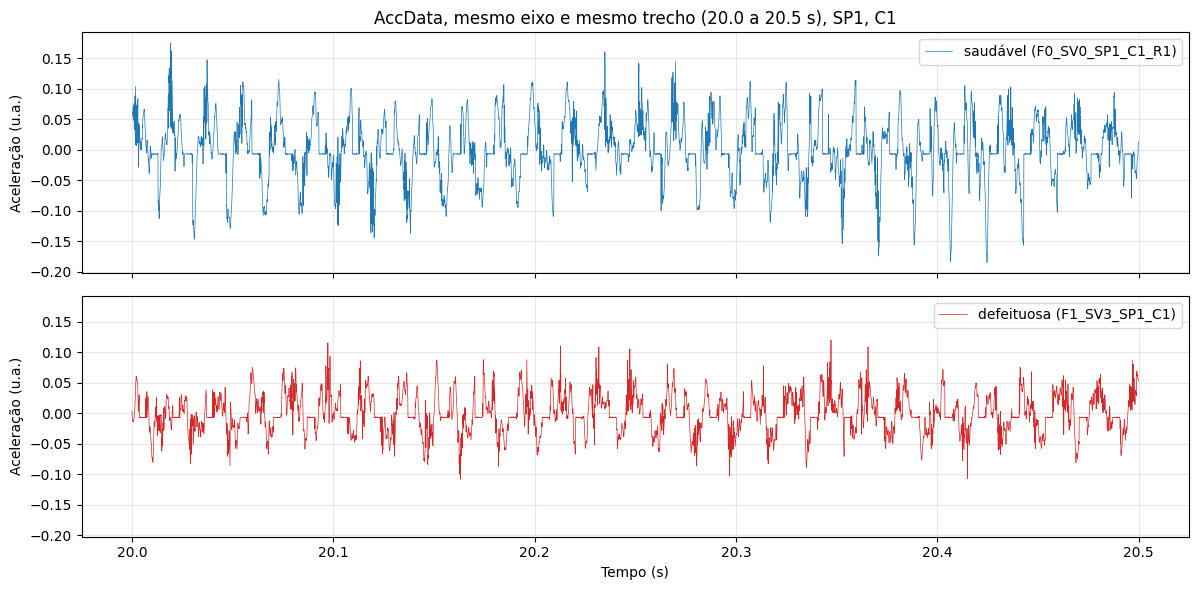

In [4]:
fs = 10000
T0, T1 = 20.0, 20.5
ARQ = {"saudavel": "F0_SV0_SP1_C1_R1.mat", "defeituoso": "F1_SV3_SP1_C1.mat"}
ROT = {"saudavel": "saudável", "defeituoso": "defeituosa"}
CORES = {"saudavel": "tab:blue", "defeituoso": "tab:red"}

i0, i1 = int(T0 * fs), int(T1 * fs)
t = np.arange(i0, i1) / fs

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, (cond, nome) in zip(axs, ARQ.items()):
    x = ler_acc(nome)[i0:i1]
    assert len(x) == len(t)
    ax.plot(t, x, lw=0.5, color=CORES[cond], label=f"{ROT[cond]} ({nome[:-4]})")
    ax.set_ylabel("Aceleração (u.a.)")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

axs[0].set_title(f"AccData, mesmo eixo e mesmo trecho ({T0:.1f} a {T1:.1f} s), SP1, C1")
axs[-1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.savefig("../results/figures/sinais_tempo_par.png", dpi=150)
plt.show()

## 2.3 Definições das características (requisito 3.2.2)

Para cada janela com N = 20000 amostras x[n]:

| Medida | Definição | Unidade | Significado |
|---|---|---|---|
| Média | $\mu = \frac{1}{N}\sum x[n]$ | u.a. | componente constante (offset do sensor) |
| Potência média | $P = \frac{1}{N}\sum x[n]^2$ | u.a.² | energia por amostra, incluindo a média |
| RMS | $\sqrt{P}$ | u.a. | intensidade da vibração, na unidade do sinal |
| Desvio padrão | $\sigma = \sqrt{\frac{1}{N}\sum (x[n]-\mu)^2}$ | u.a. | intensidade só da parte que oscila |
| Pico absoluto | $\max \lvert x[n] \rvert$ | u.a. | maior excursão, sensível a impactos isolados |
| Pico a pico | $\max x - \min x$ | u.a. | faixa total ocupada pelo sinal |
| Fator de crista | pico absoluto / RMS | adimensional | quão impulsivo é o sinal (senoide pura: √2 ≈ 1,41) |

O desvio usa divisor N, e não N − 1. Assim vale exatamente $P = \mu^2 + \sigma^2$, o que serve de teste de consistência. A célula abaixo testa as fórmulas em um registro antes de aplicá-las a todos.

In [5]:
w = get_matriz_acc(reg["arquivo"], list_janelas)

media = w.mean(axis=1)
desvio = w.std(axis=1)
pot = (w ** 2).mean(axis=1)
rms = np.sqrt(pot)
pico_abs = np.abs(w).max(axis=1)
pico_pico = w.max(axis=1) - w.min(axis=1)
crista = pico_abs / rms

print(w.shape, rms.shape)
print(rms[0], crista[0], media[0], desvio[0])
print(np.allclose(pot, media ** 2 + desvio ** 2))
print(crista.min() >= 1)

(30, 20000) (30,)
0.0444464225902886 5.332383895092938 -0.0009012549928156659 0.04443728412619792
True
True


## 2.4 Extração para todas as janelas

Aplica as mesmas fórmulas às 2370 janelas dos 99 registros. Cada linha de `features_tempo.csv` guarda `arquivo`, `id` e `rotulo`, para manter a ligação com o registro de origem. Os `assert` conferem se não há NaN, se $P = \mu^2 + \sigma^2$ e se o fator de crista é ≥ 1.

In [6]:
linhas = []
for arquivo in list_janelas["arquivo"].unique():
    g = list_janelas[list_janelas["arquivo"] == arquivo].reset_index(drop=True)
    w = get_matriz_acc(arquivo, list_janelas)

    media = w.mean(axis=1)
    desvio = w.std(axis=1)
    pot = (w ** 2).mean(axis=1)
    rms = np.sqrt(pot)
    pico_abs = np.abs(w).max(axis=1)
    pico_pico = w.max(axis=1) - w.min(axis=1)
    crista = pico_abs / rms

    parte = g[["arquivo", "id", "rotulo", "F", "SV", "SP", "C", "jan"]].copy()
    parte["media"] = media
    parte["desvio"] = desvio
    parte["potencia"] = pot
    parte["rms"] = rms
    parte["pico_abs"] = pico_abs
    parte["pico_a_pico"] = pico_pico
    parte["crista"] = crista
    linhas.append(parte)

feat_t = pd.concat(linhas, ignore_index=True)

assert len(feat_t) == len(list_janelas)
assert feat_t.isna().sum().sum() == 0
assert np.allclose(feat_t["potencia"], feat_t["media"] ** 2 + feat_t["desvio"] ** 2)
assert (feat_t["crista"] >= 1).all()
print(feat_t.groupby("rotulo").size())

feat_t.to_csv("../data/processed/features_tempo.csv", index=False)
print(feat_t.groupby("rotulo")[["media", "rms", "desvio", "pico_abs", "pico_a_pico", "crista"]].agg(["mean", "std"]).round(4).T.to_string())

rotulo
defeituoso    1890
saudavel       480
dtype: int64
rotulo            defeituoso  saudavel
media       mean     -0.0013   -0.0009
            std       0.0008    0.0006
rms         mean      0.1260    0.1141
            std       0.1154    0.0905
desvio      mean      0.1260    0.1141
            std       0.1154    0.0905
pico_abs    mean      0.5324    0.4794
            std       0.4205    0.3490
pico_a_pico mean      0.9976    0.8908
            std       0.8075    0.6598
crista      mean      4.8558    4.6886
            std       1.0195    1.0298


## 2.5 Tabela de valores das características (requisito 3.2.3)

Resumo por **SP e condição** com **mediana e IQR** de cada uma das 7 características, sobre todas as janelas de 2 s do grupo. Saída: `results/tables/caracteristicas_tempo_resumo.csv.

- **Por que separar por SP:** a intensidade da vibração cresce com a rotação. O RMS mediano vai de cerca de 0,02–0,04 u.a. em `SP1` para 0,2 u.a. em `SP3`. Juntar os SP faria a diferença entre rotações dominar a dispersão e esconder a diferença entre condições.
- **Por que mediana e IQR:** pico absoluto e fator de crista dependem de poucas amostras extremas por janela, e as distribuições não são simétricas. A mediana e o IQR são menos sensíveis a janelas atípicas do que a média e o desvio padrão.
- O resumo por rótulo com média e desvio, na célula anterior, mistura os SP e fica só como conferência.

In [7]:
# Tabela de valores: mediana e IQR por SP e condição, uma linha por janela de entrada
FEATS = {"media": "u.a.", "rms": "u.a.", "potencia": "u.a.²", "desvio": "u.a.",
         "pico_abs": "u.a.", "pico_a_pico": "u.a.", "crista": "adimensional"}
ROT = {"saudavel": "saudável", "defeituoso": "defeituosa"}

def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

g = feat_t.groupby(["SP", "rotulo"])[list(FEATS)]
med, amp = g.median(), g.agg(iqr)
n_jan = feat_t.groupby(["SP", "rotulo"]).size()
n_reg = feat_t.groupby(["SP", "rotulo"])["arquivo"].nunique()

linhas = []
for f, un in FEATS.items():
    for (sp, rot) in med.index:
        linhas.append({"característica": f, "unidade": un, "SP": sp, "condição": ROT[rot],
                       "n_reg": n_reg[(sp, rot)], "n_jan": n_jan[(sp, rot)],
                       "mediana": med.loc[(sp, rot), f], "IQR": amp.loc[(sp, rot), f]})
tab_t = pd.DataFrame(linhas)
tab_t.to_csv("../results/tables/caracteristicas_tempo_resumo.csv", index=False)

# versão larga para leitura: "mediana (IQR)" por característica
fmt = lambda m, q: f"{m:.4g} ({q:.2g})"
larga = tab_t.assign(valor=[fmt(m, q) for m, q in zip(tab_t["mediana"], tab_t["IQR"])])
larga = larga.pivot_table(index=["SP", "condição"], columns="característica", values="valor", aggfunc="first")[list(FEATS)]
larga.columns = [f"{c} [{u}]" for c, u in FEATS.items()]
display(larga)

media [u.a.]        rms [u.a.]    potencia [u.a.²]  \
SP condição                                                                 
1  defeituosa   -0.001085 (0.00028)  0.02456 (0.0085)  0.000603 (0.00043)   
   saudável    -0.0008066 (0.00037)    0.0424 (0.053)   0.001798 (0.0045)   
2  defeituosa   -0.001133 (0.00053)   0.09319 (0.022)   0.008685 (0.0041)   
   saudável    -0.0008393 (0.00058)   0.09045 (0.091)    0.008182 (0.016)   
3  defeituosa    -0.001472 (0.0011)    0.2389 (0.093)     0.05706 (0.047)   
   saudável    -0.0009865 (0.00077)      0.207 (0.15)     0.04284 (0.065)   

                  desvio [u.a.] pico_abs [u.a.] pico_a_pico [u.a.]  \
SP condição                                                          
1  defeituosa  0.02454 (0.0085)  0.1432 (0.043)      0.249 (0.064)   
   saudável      0.0424 (0.053)   0.1984 (0.22)      0.3823 (0.43)   
2  defeituosa   0.09319 (0.022)   0.4483 (0.12)      0.8367 (0.21)   
   saudável     0.09044 (0.091)   0.3926 (0.41)      0.7572 (0.77)   
3  defeituosa    0.2389 (0.093)   0.9517 (0.37)        1.807 (0.7)   
   saudável        0.207 (0.15)   0.8289 (0.62)        1.561 (1.2)   

              crista [adimensional]  
SP condição                          
1  defeituosa           5.803 (1.1)  
   saudável             5.478 (1.7)  
2  defeituosa          4.704 (0.74)  
   saudável            4.614 (0.92)  
3  defeituosa           3.954 (0.7)  
   saudável            3.753 (0.44)

## 2.6 Gráficos comparativos por SP (requisito 3.2.3)

Boxplots de RMS, desvio padrão, pico absoluto e fator de crista, **separados por SP**. Cada caixa resume as **janelas de 2 s** de uma condição em um SP: a linha é a mediana, a caixa vai de Q1 a Q3 e os bigodes chegam a 1,5 × IQR. Os outliers não são desenhados (`showfliers=False`), para não achatar as caixas.

- **Por que separar por SP:** com os SP juntos, a diferença de rotação domina. A razão do RMS mediano defeituosa/saudável é 0,58 em `SP1`, 1,03 em `SP2` e 1,15 em `SP3`. O sentido se inverte entre os SP, e misturá-los esconde isso.
- **Escala log** nas medidas de amplitude: o RMS muda cerca de 10 vezes entre `SP1` e `SP3`, e em escala linear as caixas do `SP1` ficariam achatadas. O fator de crista é adimensional e fica em escala linear.
- As caixas tratam janelas como observações. Janelas do mesmo registro não são independentes, e os saudáveis têm só 3 registros por grupo de SP e C. Por isso, a largura das caixas não deve ser lida como incerteza.

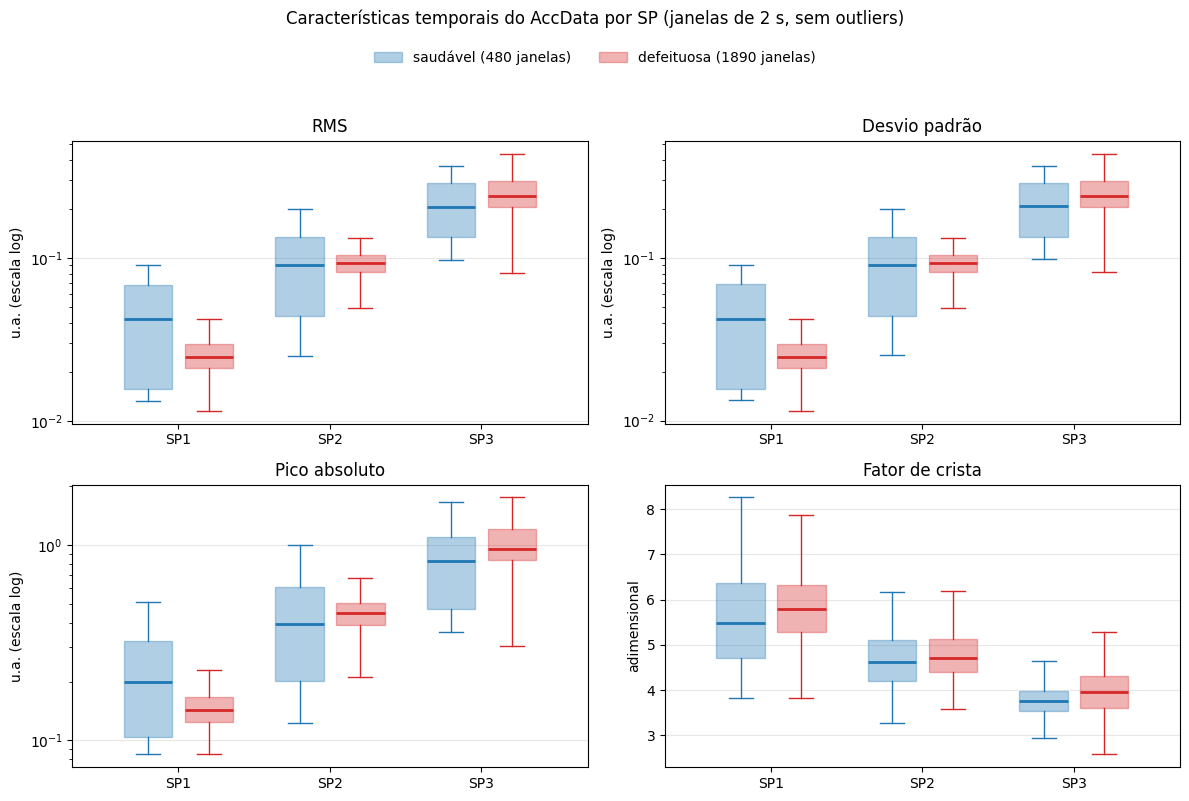

In [8]:
# Boxplots por SP: cada caixa resume as janelas de 2 s de uma condição em um SP
from matplotlib.patches import Patch

COLS = {"rms": ("RMS", "u.a."), "desvio": ("Desvio padrão", "u.a."),
        "pico_abs": ("Pico absoluto", "u.a."), "crista": ("Fator de crista", "adimensional")}
CONDS = [("saudavel", "saudável", "tab:blue"), ("defeituoso", "defeituosa", "tab:red")]
SPS = sorted(feat_t["SP"].unique())
DESL = {"saudavel": -0.2, "defeituoso": 0.2}

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for ax, (c, (nome, un)) in zip(axs.flat, COLS.items()):
    for cond, _, cor in CONDS:
        dados = [feat_t.loc[(feat_t["SP"] == sp) & (feat_t["rotulo"] == cond), c] for sp in SPS]
        pos = [i + DESL[cond] for i in range(len(SPS))]
        ax.boxplot(dados, positions=pos, widths=0.32, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=cor, alpha=0.35, edgecolor=cor),
                   medianprops=dict(color=cor, lw=2),
                   whiskerprops=dict(color=cor), capprops=dict(color=cor))
    ax.set_xticks(range(len(SPS)))
    ax.set_xticklabels([f"SP{sp}" for sp in SPS])
    ax.set_title(nome)
    ax.set_ylabel(un)
    if c != "crista":
        ax.set_yscale("log")  # a amplitude muda cerca de 10x entre SP1 e SP3
        ax.set_ylabel(f"{un} (escala log)")
    ax.grid(axis="y", alpha=0.3)

n = feat_t.groupby("rotulo").size()
fig.legend(handles=[Patch(facecolor=cor, alpha=0.35, edgecolor=cor, label=f"{rot} ({n[cond]} janelas)")
                    for cond, rot, cor in CONDS], loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=2, frameon=False)
fig.suptitle("Características temporais do AccData por SP (janelas de 2 s, sem outliers)", y=0.995)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.savefig("../results/figures/boxplots_tempo.png", dpi=150)
plt.show()

## 2.7 RMS × potência média e efeito da componente média (requisito 3.2.4)

A potência média de uma janela se divide em duas partes:

$$P = \frac{1}{N}\sum x[n]^2 = \mu^2 + \sigma^2, \qquad \text{RMS} = \sqrt{P} = \sqrt{\mu^2 + \sigma^2}$$

- $\mu^2$ é a potência da componente constante (média).
- $\sigma^2$ é a potência da parte que oscila, que é a vibração em si.

A célula abaixo mede, para cada janela, quanto da potência vem da média ($\mu^2/P$) e quanto o RMS difere do desvio padrão.

μ²/P, (RMS − σ)/RMS e |μ|/RMS por SP (mediana e máximo das janelas):
   frac_media         dif_rms_desvio         media_sobre_rms        
       median     max         median     max          median     max
SP                                                                  
1      0.1877  0.9246         0.0939  0.4634          4.3321  9.6156
2      0.0173  0.1750         0.0086  0.0875          1.3148  4.1832
3      0.0039  0.0405         0.0019  0.0202          0.6227  2.0123 
(valores em %)

Média por condição e SP (mediana das janelas, u.a.):
rotulo  defeituoso  saudavel
SP                          
1         -0.00109  -0.00081
2         -0.00113  -0.00084
3         -0.00147  -0.00099


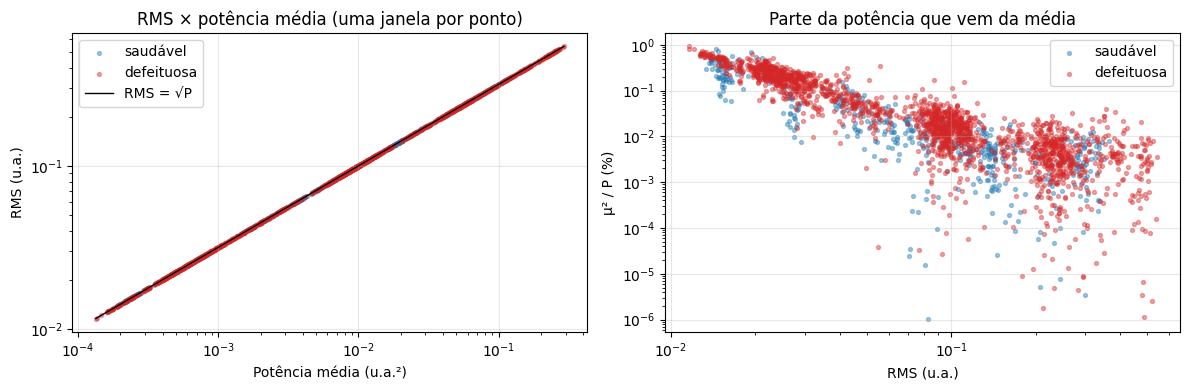

In [9]:
# RMS × potência média e efeito da componente média, por janela
d = feat_t.copy()
d["frac_media"] = d["media"] ** 2 / d["potencia"]           
d["dif_rms_desvio"] = (d["rms"] - d["desvio"]) / d["rms"]   
d["media_sobre_rms"] = d["media"].abs() / d["rms"]          

assert np.allclose(d["rms"], np.sqrt(d["potencia"]))        
res = d.groupby("SP")[["frac_media", "dif_rms_desvio", "media_sobre_rms"]].agg(["median", "max"])
print("μ²/P, (RMS − σ)/RMS e |μ|/RMS por SP (mediana e máximo das janelas):")
print((100 * res).round(4).to_string(), "\n(valores em %)")

# a componente média tem o mesmo sinal e tamanho nas duas condições?
print("\nMédia por condição e SP (mediana das janelas, u.a.):")
print(d.groupby(["SP", "rotulo"])["media"].median().unstack().round(5).to_string())

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for cond, rot, cor in CONDS:
    m = d["rotulo"] == cond
    axs[0].scatter(d.loc[m, "potencia"], d.loc[m, "rms"], s=8, alpha=0.4, color=cor, label=rot)
    axs[1].scatter(d.loc[m, "rms"], 100 * d.loc[m, "frac_media"], s=8, alpha=0.4, color=cor, label=rot)
p = np.geomspace(d["potencia"].min(), d["potencia"].max(), 100)
axs[0].plot(p, np.sqrt(p), color="k", lw=1, label="RMS = √P")
axs[0].set(xscale="log", yscale="log", xlabel="Potência média (u.a.²)", ylabel="RMS (u.a.)",
           title="RMS × potência média (uma janela por ponto)")
axs[1].set(xscale="log", yscale="log", xlabel="RMS (u.a.)", ylabel="μ² / P (%)",
           title="Parte da potência que vem da média")
for ax in axs:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("../results/figures/rms_potencia_media.png", dpi=150)
plt.show()

**Interpretação**

- **RMS e potência média carregam a mesma informação.** O RMS é só a raiz da potência. A diferença está na unidade e na escala. O RMS fica na unidade do sinal (u.a.) e cresce linearmente com a amplitude. A potência fica em u.a.² e cresce com o quadrado da amplitude, então exagera as diferenças: uma janela com o dobro do RMS tem quatro vezes a potência. Para classificar, usar as duas é redundante.
- **A componente média é desprezível no `AccData`.** A média fica em cerca de −0,001 u.a., enquanto o RMS vai de 0,01 a 0,5 u.a. Na mediana das janelas, $\mu^2/P$ é 0,19% em `SP1`, 0,017% em `SP2` e 0,004% em `SP3`, e nunca passa de 1%. Por isso, RMS e desvio padrão diferem em menos de 0,1% na mediana, e no máximo 0,5% no pior caso, sempre em janelas de `SP1` com RMS baixo (gráfico da direita).
- **Consequência:** RMS ≈ desvio padrão e potência ≈ variância. As três medidas são praticamente uma só, e basta manter uma delas no conjunto de características.
- **Quando a média importaria:** se o sinal tivesse um offset grande, como o canal 3 da IMU com a gravidade (≈ 9,7), $\mu^2$ dominaria P, e o RMS mediria o offset, não a vibração. Nesse caso, a vibração seria medida pelo desvio padrão, ou pelo RMS depois de subtrair a média da janela. No `AccData` isso não é necessário, mas o notebook 3 subtrai a média antes da FFT para tirar o bin de 0 Hz.
- **A média é ligeiramente mais negativa nos defeituosos** (−0,0011 a −0,0015 contra −0,0008 a −0,0010 u.a.) nos três SP. A seção 2.8 mostra que isso acompanha a **data de aquisição**, e não a condição: comparando só registros de setembro, as médias de saudáveis e defeituosos ficam praticamente iguais.

## 2.8 Análise das características temporais (requisito 3.2.4)

Os boxplots da seção 2.6 juntam os `C` e usam janelas. Aqui a comparação é feita **por registro** (mediana das janelas de cada arquivo), separando `SP`, `C` e o **mês de aquisição** (`AccData.DATE`). Os defeituosos foram todos gravados em setembro de 2024. Dos saudáveis, só o `R1` de cada grupo é de setembro, e o `R2` e o `R3` são de novembro. A célula também calcula a correlação entre as medidas, para avaliar a redundância.

In [10]:
# Análise por registro: mediana das janelas de cada registro, separando SP, C e mês de aquisição
import scipy.io as sio
from src.io_utils import DATA_DIR

def data_aquisicao(nome):
    m = sio.loadmat(DATA_DIR / nome, simplify_cells=True, variable_names=["AccData"])
    return m["AccData"]["DATE"]

F7 = ["media", "rms", "potencia", "desvio", "pico_abs", "pico_a_pico", "crista"]
reg_t = feat_t.groupby(["arquivo", "rotulo", "SP", "C"])[F7].median().reset_index()
reg_t["data"] = reg_t["arquivo"].map(data_aquisicao)
reg_t["mes"] = pd.to_datetime(reg_t["data"], format="%d-%b-%Y").dt.month.map({9: "set", 11: "nov"})
print("Registros por condição e mês de aquisição:")
print(pd.crosstab(reg_t["rotulo"], reg_t["mes"]).to_string())

# (1) comparação dentro do mesmo SP e C (C2 fica de fora porque não tem saudável)
cols = ["media", "rms", "pico_abs", "crista"]
comp = (reg_t[reg_t["C"] != 2]
        .groupby(["SP", "C", "rotulo", "mes"])[cols].median()
        .rename(index={"saudavel": "saudável", "defeituoso": "defeituosa"}))
comp.insert(0, "n_reg", reg_t[reg_t["C"] != 2].groupby(["SP", "C", "rotulo", "mes"]).size().values)
print("\nMediana por registro, por SP, C, condição e mês (u.a.; crista adimensional):")
print(comp.round(4).to_string())

# (2) efeito de C nos saudáveis: RMS C1 / C3
s = reg_t[reg_t["rotulo"] == "saudavel"].groupby(["SP", "C"])["rms"].median().unstack()
print("\nSaudáveis, RMS mediano por registro: C1 / C3 =", (s[1] / s[3]).round(2).to_dict())

# (3) redundância: correlação de Spearman entre as medidas, por janela, dentro de cada SP
corr = sum(feat_t[feat_t["SP"] == sp][F7].corr("spearman") for sp in SPS) / len(SPS)
print("\nCorrelação de Spearman média entre SP (janelas):")
print(corr.round(2).to_string())

Registros por condição e mês de aquisição:
mes         nov  set
rotulo              
defeituoso    0   81
saudavel     12    6

Mediana por registro, por SP, C, condição e mês (u.a.; crista adimensional):
                     n_reg   media     rms  pico_abs  crista
SP C rotulo     mes                                         
1  1 defeituosa set      9 -0.0011  0.0251    0.1408  5.6273
     saudável   nov      2 -0.0007  0.0740    0.3537  4.8983
                set      1 -0.0010  0.0444    0.2049  4.6597
   3 defeituosa set      9 -0.0010  0.0152    0.1011  6.7956
     saudável   nov      2 -0.0008  0.0162    0.1044  6.4375
                set      1 -0.0009  0.0145    0.0942  6.4720
2  1 defeituosa set      9 -0.0012  0.0920    0.4472  4.8001
     saudável   nov      2 -0.0009  0.1469    0.6769  4.5411
                set      1 -0.0012  0.0930    0.4272  4.7121
   3 defeituosa set      9 -0.0010  0.0480    0.2108  4.2590
     saudável   nov      2 -0.0007  0.0408    0.1830  4.6614
  

### Quais medidas diferem entre as condições?

**Nenhuma medida temporal separa as condições de forma consistente.** A impressão de diferença nos boxplots vem, em boa parte, de dois fatores que não são a hélice:

1. **O `C` muda a amplitude mais que a condição.** Nos saudáveis, o RMS do `C1` é 4,4, 3,2 e 2,2 vezes o do `C3` (em `SP1`, `SP2` e `SP3`). Com os `C` juntos, os saudáveis ficam com caixas muito largas (seção 2.6). Isso é variação entre configurações de ensaio, não ruído.
2. **A data de aquisição.** Os saudáveis de novembro têm RMS e pico maiores que o saudável de setembro do mesmo grupo. Exemplos: 0,074 contra 0,044 u.a. em `SP1`/`C1`, e 0,147 contra 0,093 em `SP2`/`C1`. Como todos os defeituosos são de setembro, a comparação com todos os saudáveis mistura o efeito do defeito com o da data.

**Comparando só os registros de setembro**, que têm mesmo SP, mesmo C e mesma época:
- **RMS, desvio e pico** ficam muito próximos na maioria dos grupos. Por exemplo, `SP2`/`C1` tem 0,092 nos defeituosos contra 0,093 no saudável, e `SP1`/`C3` tem 0,0152 contra 0,0145. A exceção é `SP1`/`C1`, onde o defeituoso tem cerca de metade do RMS do saudável (0,025 contra 0,044).
- **Fator de crista:** é maior nos defeituosos em 5 dos 6 grupos (todos menos `SP2`/`C3`). A diferença vai de 0,1 a 1,0 e é maior em `SP1`/`C1` (5,63 contra 4,66). Entre saudáveis do mesmo grupo gravados em datas diferentes, o fator de crista varia até 0,65, então só a diferença de `SP1`/`C1` passa claramente dessa variação. É a medida temporal mais promissora, mas a evidência é fraca.
- **Média:** fica praticamente igual entre as condições (cerca de −0,001 u.a.). A diferença vista em 2.7 é efeito da data.

**Ressalva:** em cada grupo de SP e C há **um único saudável de setembro**. Qualquer diferença acima depende de um registro só e não pode ser generalizada.

### Quais medidas se comportam de forma parecida e quais são redundantes?

Correlação de Spearman entre janelas, dentro de cada SP:

| Par | ρ | Leitura |
|---|---|---|
| RMS × desvio × potência | 1,00 | **redundantes**: mesma informação (seção 2.7) |
| pico absoluto × pico a pico | 0,98 | **redundantes**: o sinal é quase simétrico em torno de zero, e o pico a pico fica entre 1,8 e 1,9 vezes o pico absoluto (mediana por SP) |
| RMS × pico absoluto | 0,91 | **muito parecidas**: o pico cresce junto com a intensidade |
| fator de crista × RMS | −0,29 | **pouco relacionadas**: o fator de crista descreve a forma do sinal, não a intensidade |
| média × demais | ≈ −0,17 | **independente** da vibração |

Na prática há **três tipos de informação**: intensidade (RMS ≈ desvio ≈ √potência, e os picos acompanham), forma (fator de crista) e offset (média). Um conjunto mínimo e não redundante seria **RMS, pico absoluto e fator de crista**. A média não deve ir para o classificador, porque funcionaria como um marcador da data de aquisição, e não da hélice.

### Conclusões para as próximas etapas

- No domínio do tempo, a diferença entre condições é pequena perto da variação causada por `SP`, `C` e data. Isso motiva a análise espectral (notebook 3): um defeito pode mudar **como** a energia se distribui em frequência, mesmo sem mudar o total.
- Na classificação (3.5), a divisão treino/teste por registro é necessária. Também vale verificar se o modelo não está só aprendendo `SP`, `C` ou a data. Uma forma de verificar é avaliar só com registros de setembro.